# BÁO CÁO MÔ HÌNH HỌC MÁY
# MÔ HÌNH 2: HIERARCHICAL CLUSTERING (BASELINE TRÊN DỮ LIỆU SẠCH CƠ BẢN)
**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)

Notebook này thực hiện huấn luyện và kiểm thử mô hình cơ sở (**Baseline**) phân cụm thứ bậc Hierarchical Clustering (Agglomerative) với $K=4$ (Ward Linkage) **trên tập dữ liệu giao dịch sạch cơ bản** (`data/train.csv`, `data/valid.csv`, `data/test.csv`) **chưa qua rút trích đặc trưng RFM**:
- **Dữ liệu đầu vào:** Tập dữ liệu giao dịch đã làm sạch sau giai đoạn EDA.
- **Thuộc tính cơ bản sử dụng:** `Quantity`, `UnitPrice`, `TotalPrice`.
- **Phương pháp tiếp cận:** Sử dụng mẫu đại diện Train để xây dựng cây phân cấp (Dendrogram), huấn luyện mô hình phân cụm thứ bậc và áp dụng tâm cụm (Nearest Centroid) để kiểm định trên Validation và Test.

In [3]:
import os
import sys
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

# Tự động tìm và chuyển về thư mục gốc dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

PROJECT_ROOT = current
os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import NearestCentroid
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

from Source.init import PATH_EXPERIMENT_LOG

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print(f"✅ Môi trường sẵn sàng tại thư mục gốc: {os.getcwd()}")
print(f"📋 Đường dẫn file nhật ký thực nghiệm: {PATH_EXPERIMENT_LOG}")

✅ Môi trường sẵn sàng tại thư mục gốc: c:\Users\Quân\Desktop\ml_group
📋 Đường dẫn file nhật ký thực nghiệm: c:\Users\Quân\Desktop\ml_group\Experiment_Log_Comparison.csv


### 1. Nạp tập dữ liệu giao dịch sạch cơ bản (Train / Validation / Test)
Nạp dữ liệu từ các file `data/train.csv`, `data/valid.csv`, `data/test.csv`.

In [4]:
train_df = pd.read_csv("data/train.csv")
val_df = pd.read_csv("data/valid.csv")
test_df = pd.read_csv("data/test.csv")

print(f"📊 Tập Train:      {train_df.shape[0]:,} dòng giao dịch")
print(f"📊 Tập Validation: {val_df.shape[0]:,} dòng giao dịch")
print(f"📊 Tập Test:       {test_df.shape[0]:,} dòng giao dịch")

print("\n\n--- 5 Dòng dữ liệu giao dịch Train mẫu ---")
print(train_df[['CustomerID', 'Quantity', 'UnitPrice', 'TotalPrice', 'Country']].head())

📊 Tập Train:      251,501 dòng giao dịch
📊 Tập Validation: 72,685 dòng giao dịch
📊 Tập Test:       74,785 dòng giao dịch


--- 5 Dòng dữ liệu giao dịch Train mẫu ---
   CustomerID  Quantity  UnitPrice  TotalPrice         Country
0       13085        12       6.95        83.4  United Kingdom
1       13085        12       6.75        81.0  United Kingdom
2       13085        12       6.75        81.0  United Kingdom
3       13085        48       2.10       100.8  United Kingdom
4       13085        24       1.25        30.0  United Kingdom


### 2. Chuẩn hóa thang đo (StandardScaler) trên thuộc tính cơ bản
Sử dụng 3 thuộc tính: `['Quantity', 'UnitPrice', 'TotalPrice']`. Fit scaler duy nhất trên tập Train để chống rò rỉ dữ liệu.

In [5]:
features = ['Quantity', 'UnitPrice', 'TotalPrice']

X_train_raw = train_df[features]
X_val_raw = val_df[features]
X_test_raw = test_df[features]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

print("✅ Đã chuẩn hóa dữ liệu giao dịch cơ bản:")
print("   - Mean (Train):", scaler.mean_.round(3))
print("   - Scale/Std (Train):", scaler.scale_.round(3))

✅ Đã chuẩn hóa dữ liệu giao dịch cơ bản:
   - Mean (Train): [12.607  2.923 21.93 ]
   - Scale/Std (Train): [31.994  2.947 62.066]


### 3. Vẽ biểu đồ Dendrogram minh họa cấu trúc phân cấp
Do thuật toán Hierarchical Clustering có độ phức tạp bộ nhớ $O(N^2)$, ta trích xuất một mẫu đại diện (sample 300 giao dịch) để hiển thị cây phân cấp Dendrogram một cách nhanh chóng và rõ nét.

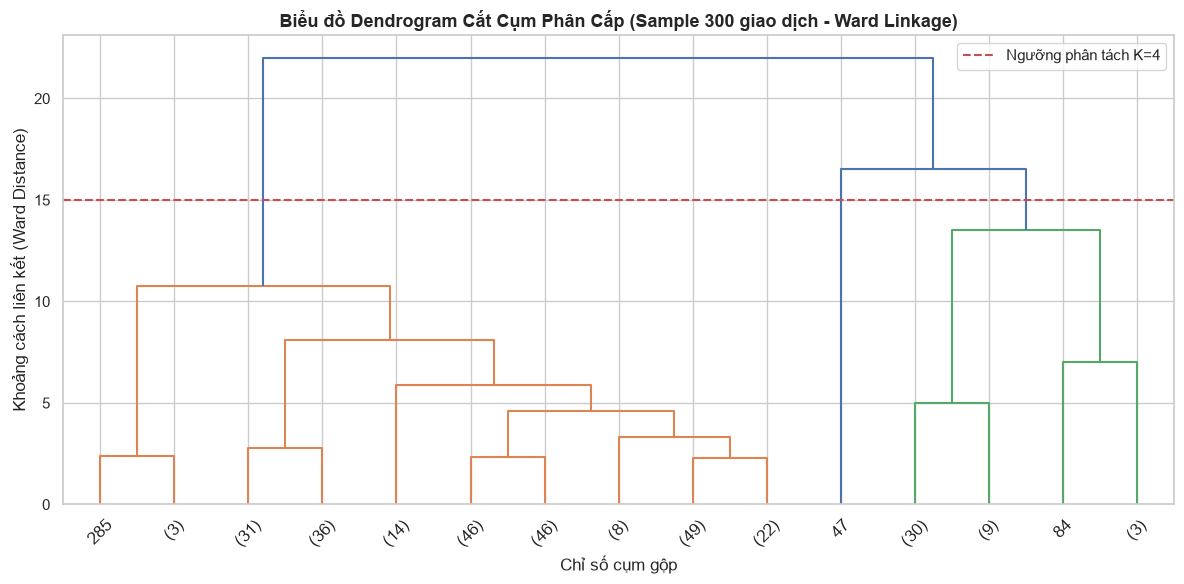

In [6]:
np.random.seed(42)
dendro_sample_size = min(300, len(X_train_scaled))
sample_idx = np.random.choice(len(X_train_scaled), size=dendro_sample_size, replace=False)
X_dendro_sample = X_train_scaled[sample_idx]

Z = linkage(X_dendro_sample, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=15, show_leaf_counts=True, leaf_rotation=45)
plt.title(f"Biểu đồ Dendrogram Cắt Cụm Phân Cấp (Sample {dendro_sample_size} giao dịch - Ward Linkage)", fontsize=13, fontweight='bold')
plt.xlabel("Chỉ số cụm gộp")
plt.ylabel("Khoảng cách liên kết (Ward Distance)")
plt.axhline(y=15, color='r', linestyle='--', label='Ngưỡng phân tách K=4')
plt.legend()
plt.tight_layout()
plt.show()

### 4. Huấn luyện mô hình Hierarchical Baseline ($K=4$, Ward Linkage)
Sử dụng mẫu đại diện Train ($N=5,000$ mẫu ngẫu nhiên có kiểm soát hạt giống `random_state=42`) để huấn luyện mô hình Hierarchical với các thông số:
- `n_clusters = 4`
- `linkage = 'ward'`

In [7]:
k_baseline = 4
train_sample_size = min(5000, len(X_train_scaled))
np.random.seed(42)
train_subset_idx = np.random.choice(len(X_train_scaled), size=train_sample_size, replace=False)

X_train_sub = X_train_scaled[train_subset_idx]
train_df_sub = train_df.iloc[train_subset_idx].copy()

hierarchical_baseline = AgglomerativeClustering(n_clusters=k_baseline, linkage='ward')
train_labels = hierarchical_baseline.fit_predict(X_train_sub)
train_df_sub['Cluster'] = train_labels

# Huấn luyện mô hình Nearest Centroid để gán nhãn cho Validation và Test
clf_centroid = NearestCentroid()
clf_centroid.fit(X_train_sub, train_labels)

print(f"✅ Đã huấn luyện xong Hierarchical Baseline K={k_baseline} trên tập mẫu Train ({train_sample_size:,} mẫu)!")

✅ Đã huấn luyện xong Hierarchical Baseline K=4 trên tập mẫu Train (5,000 mẫu)!


### 5. Đánh giá chất lượng phân cụm trên cả 3 tập: Train, Validation và Test
Áp dụng phân loại Nearest Centroid để dự đoán nhãn cho tập Validation và Test.

In [8]:
val_sample_size = min(5000, len(X_val_scaled))
test_sample_size = min(5000, len(X_test_scaled))

np.random.seed(42)
val_sub_idx = np.random.choice(len(X_val_scaled), size=val_sample_size, replace=False)
test_sub_idx = np.random.choice(len(X_test_scaled), size=test_sample_size, replace=False)

X_val_sub = X_val_scaled[val_sub_idx]
X_test_sub = X_test_scaled[test_sub_idx]

val_labels = clf_centroid.predict(X_val_sub)
test_labels = clf_centroid.predict(X_test_sub)

# 1. Đánh giá Train
sil_train = silhouette_score(X_train_sub, train_labels)
db_train = davies_bouldin_score(X_train_sub, train_labels)
ch_train = calinski_harabasz_score(X_train_sub, train_labels)

# 2. Đánh giá Validation
sil_val = silhouette_score(X_val_sub, val_labels)
db_val = davies_bouldin_score(X_val_sub, val_labels)
ch_val = calinski_harabasz_score(X_val_sub, val_labels)

# 3. Đánh giá Test
sil_test = silhouette_score(X_test_sub, test_labels)
db_test = davies_bouldin_score(X_test_sub, test_labels)
ch_test = calinski_harabasz_score(X_test_sub, test_labels)

print("=" * 70)
print(f"📊 BẢNG KẾT QUẢ ĐÁNH GIÁ HIERARCHICAL BASELINE (K={k_baseline}) TRÊN DATA CLEAN:")
print("=" * 70)
print(f"Tập Huấn luyện (Train):      Silhouette = {sil_train:.4f} | Davies-Bouldin = {db_train:.4f} | Calinski-Harabasz = {ch_train:,.2f}")
print(f"Tập Kiểm định (Validation):  Silhouette = {sil_val:.4f} | Davies-Bouldin = {db_val:.4f} | Calinski-Harabasz = {ch_val:,.2f}")
print(f"Tập Kiểm thử (Test):         Silhouette = {sil_test:.4f} | Davies-Bouldin = {db_test:.4f} | Calinski-Harabasz = {ch_test:,.2f}")
print("=" * 70)

📊 BẢNG KẾT QUẢ ĐÁNH GIÁ HIERARCHICAL BASELINE (K=4) TRÊN DATA CLEAN:
Tập Huấn luyện (Train):      Silhouette = 0.6258 | Davies-Bouldin = 0.6843 | Calinski-Harabasz = 3,130.95
Tập Kiểm định (Validation):  Silhouette = 0.6154 | Davies-Bouldin = 0.6215 | Calinski-Harabasz = 2,681.96
Tập Kiểm thử (Test):         Silhouette = 0.6398 | Davies-Bouldin = 0.6005 | Calinski-Harabasz = 2,355.78


### 6. Phân tích chân dung các cụm giao dịch (Cluster Profiling)
Thống kê số lượng bản ghi và giá trị trung bình của `Quantity`, `UnitPrice`, `TotalPrice` theo từng cụm.

In [9]:
profile = train_df_sub.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Quantity': 'mean',
    'UnitPrice': 'mean',
    'TotalPrice': 'mean'
}).rename(columns={'CustomerID': 'SoLuong_BanGhi'})

profile['TyLe_%'] = (profile['SoLuong_BanGhi'] / len(train_df_sub) * 100).round(2)
profile['Quantity'] = profile['Quantity'].round(2)
profile['UnitPrice'] = profile['UnitPrice'].round(2)
profile['TotalPrice'] = profile['TotalPrice'].round(2)

print("--- THỐNG KÊ ĐẶC TRƯNG CỤM GIAO DỊCH CƠ BẢN (HIERARCHICAL TRAIN) ---")
print(profile[['SoLuong_BanGhi', 'TyLe_%', 'Quantity', 'UnitPrice', 'TotalPrice']])

--- THỐNG KÊ ĐẶC TRƯNG CỤM GIAO DỊCH CƠ BẢN (HIERARCHICAL TRAIN) ---
         SoLuong_BanGhi  TyLe_%  Quantity  UnitPrice  TotalPrice
Cluster                                                         
0                  4179   83.58     10.93       1.95       15.68
1                    57    1.14    219.65       1.35      237.30
2                   758   15.16      4.34       8.53       29.83
3                     6    0.12    326.67       4.86     1143.13


### 7. Đánh giá thuộc tính nào đóng góp nhiều nhất vào việc phân cụm
Để xác định thuộc tính chi phối mạnh nhất đến việc phân cụm thứ bậc Hierarchical Clustering, ta sử dụng 2 thước đo định lượng:
1. **Tọa độ tâm cụm (Nearest Centroids):** Đo độ lệch chuẩn (Std) của tâm các cụm trên không gian chuẩn hóa Z-score.
2. **Kiểm định ANOVA F-Score (`f_classif`):** Đo tỷ số phân tán giữa các cụm trên phân tán nội cụm để tính chính xác tỷ lệ % mức độ đóng góp của từng thuộc tính.

📊 BẢNG XẾP HẠNG THUỘC TÍNH ĐÓNG GÓP NHIỀU NHẤT (HIERARCHICAL):
   Thuộc tính  Độ phân tách tâm cụm (Std)  ANOVA F-Score  Tỷ lệ đóng góp (%)
0  TotalPrice                      7.4528        3843.05               39.86
1   UnitPrice                      0.9653        2900.09               30.08
2    Quantity                      4.3154        2897.75               30.06
👉 KẾT LUẬN: Hierarchical Clustering gom cụm dựa trên thuộc tính [TotalPrice] nhiều nhất (39.86%).


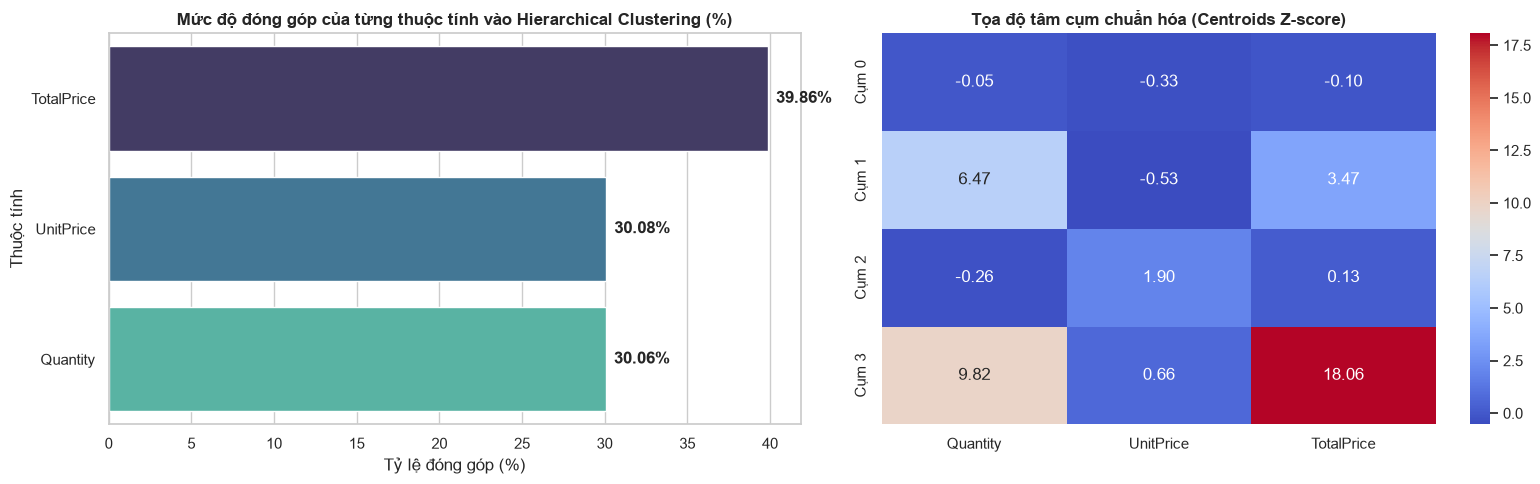

In [10]:
from sklearn.feature_selection import f_classif

# 1. Trích xuất tọa độ tâm cụm từ NearestCentroid đã học
centers = clf_centroid.centroids_
df_centers = pd.DataFrame(centers, columns=features, index=[f"Cụm {i}" for i in range(k_baseline)])

# 2. Tính độ lệch chuẩn (Std) giữa các tâm cụm theo từng thuộc tính
centroid_std = np.std(centers, axis=0)

# 3. Tính ANOVA F-Score để đo mức độ phân biệt giữa các cụm
f_scores, p_values = f_classif(X_train_sub, train_labels)
feature_importance = (f_scores / f_scores.sum()) * 100

# 4. Tổng hợp bảng xếp hạng mức độ ảnh hưởng của các thuộc tính
ranking_df = pd.DataFrame({
    'Thuộc tính': features,
    'Độ phân tách tâm cụm (Std)': centroid_std.round(4),
    'ANOVA F-Score': f_scores.round(2),
    'Tỷ lệ đóng góp (%)': feature_importance.round(2)
}).sort_values(by='Tỷ lệ đóng góp (%)', ascending=False).reset_index(drop=True)

print("=" * 65)
print("📊 BẢNG XẾP HẠNG THUỘC TÍNH ĐÓNG GÓP NHIỀU NHẤT (HIERARCHICAL):")
print("=" * 65)
print(ranking_df)
print("=" * 65)

top_feature = ranking_df.iloc[0]['Thuộc tính']
top_percent = ranking_df.iloc[0]['Tỷ lệ đóng góp (%)']
print(f"👉 KẾT LUẬN: Hierarchical Clustering gom cụm dựa trên thuộc tính [{top_feature}] nhiều nhất ({top_percent}%).")

# 5. Trực quan hóa mức độ đóng góp và tọa độ tâm cụm
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ thanh tỷ lệ đóng góp
sns.barplot(data=ranking_df, x='Tỷ lệ đóng góp (%)', y='Thuộc tính', palette='mako', ax=ax1)
ax1.set_title("Mức độ đóng góp của từng thuộc tính vào Hierarchical Clustering (%)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Tỷ lệ đóng góp (%)")
for i, v in enumerate(ranking_df['Tỷ lệ đóng góp (%)']):
    ax1.text(v + 0.5, i, f"{v:.2f}%", va='center', fontweight='bold')

# Biểu đồ Heatmap tọa độ tâm cụm (Z-score)
sns.heatmap(df_centers, annot=True, cmap="coolwarm", fmt=".2f", ax=ax2, cbar=True)
ax2.set_title("Tọa độ tâm cụm chuẩn hóa (Centroids Z-score)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 8. Trực quan hóa phân cụm (2D PCA Visualization & Biểu đồ đặc trưng)


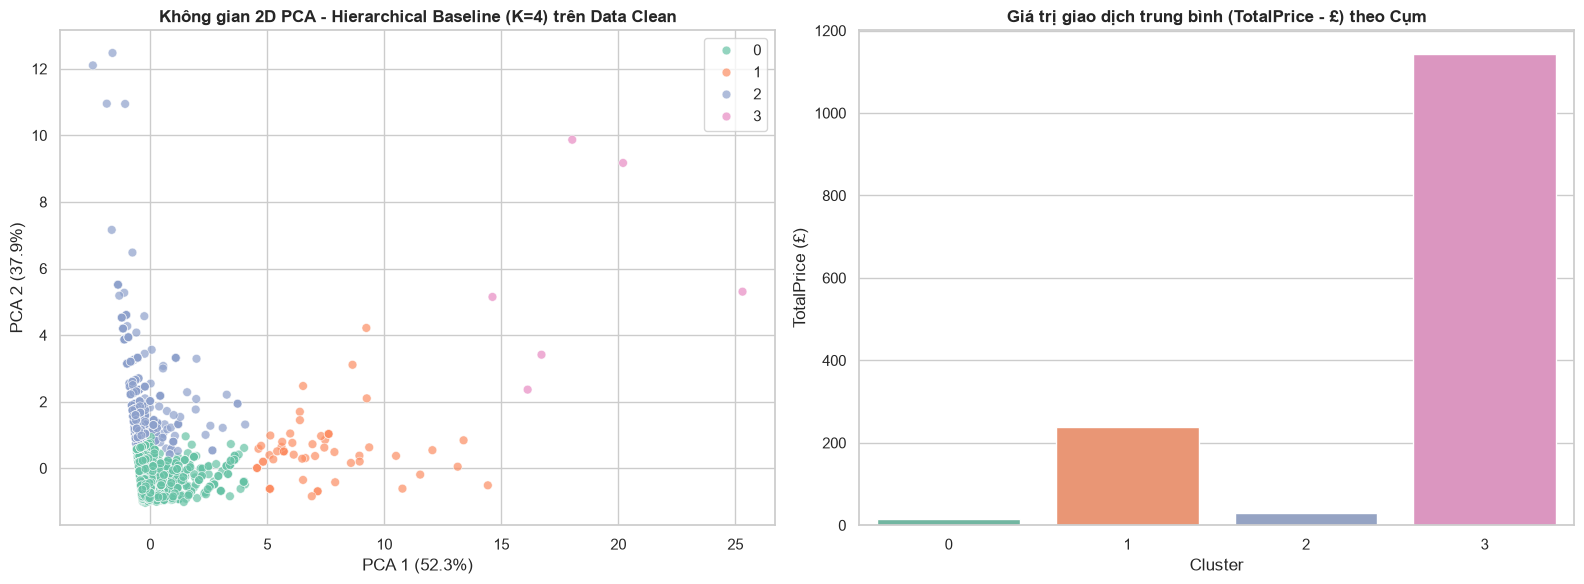

In [11]:
pca = PCA(n_components=2, random_state=42)
X_sub_pca = pca.fit_transform(X_train_sub)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Scatter PCA 2D
sns.scatterplot(
    x=X_sub_pca[:, 0], y=X_sub_pca[:, 1], hue=train_labels,
    palette='Set2', alpha=0.7, s=40, ax=ax1
)
ax1.set_title(f"Không gian 2D PCA - Hierarchical Baseline (K={k_baseline}) trên Data Clean", fontsize=12, fontweight='bold')
ax1.set_xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax1.set_ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")

# Biểu đồ cột TotalPrice trung bình theo Cụm
sns.barplot(data=profile.reset_index(), x='Cluster', y='TotalPrice', palette='Set2', ax=ax2)
ax2.set_title("Giá trị giao dịch trung bình (TotalPrice - £) theo Cụm", fontsize=12, fontweight='bold')
ax2.set_ylabel("TotalPrice (£)")

plt.tight_layout()
plt.show()

### 9. Ghi nhận kết quả vào nhật ký thực nghiệm `Experiment_Log_Comparison.csv`


In [12]:
now_str = dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S")

entries = [
    {
        'Timestamp': now_str,
        'Model': f"Hierarchical Baseline (K={k_baseline}, Ward, Data Clean) - Train",
        'Silhouette': round(sil_train, 4),
        'Davies-Bouldin': round(db_train, 4),
        'Calinski-Harabasz': round(ch_train, 2)
    },
    {
        'Timestamp': now_str,
        'Model': f"Hierarchical Baseline (K={k_baseline}, Ward, Data Clean) - Validation",
        'Silhouette': round(sil_val, 4),
        'Davies-Bouldin': round(db_val, 4),
        'Calinski-Harabasz': round(ch_val, 2)
    },
    {
        'Timestamp': now_str,
        'Model': f"Hierarchical Baseline (K={k_baseline}, Ward, Data Clean) - Test",
        'Silhouette': round(sil_test, 4),
        'Davies-Bouldin': round(db_test, 4),
        'Calinski-Harabasz': round(ch_test, 2)
    }
]

df_entries = pd.DataFrame(entries)

if not os.path.exists(PATH_EXPERIMENT_LOG):
    df_entries.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='w')
else:
    df_entries.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='a', header=False)

print(f"💾 Đã lưu thành công 3 kết quả thực nghiệm vào: {PATH_EXPERIMENT_LOG}")
print(df_entries)

💾 Đã lưu thành công 3 kết quả thực nghiệm vào: c:\Users\Quân\Desktop\ml_group\Experiment_Log_Comparison.csv
             Timestamp                                              Model  \
0  2026-11-17 20:47:49  Hierarchical Baseline (K=4, Ward, Data Clean) ...   
1  2026-11-17 20:47:49  Hierarchical Baseline (K=4, Ward, Data Clean) ...   
2  2026-11-17 20:47:49  Hierarchical Baseline (K=4, Ward, Data Clean) ...   

   Silhouette  Davies-Bouldin  Calinski-Harabasz  
0      0.6258          0.6843            3130.95  
1      0.6154          0.6215            2681.96  
2      0.6398          0.6005            2355.78  


---
## TỔNG KẾT MÔ HÌNH HIERARCHICAL BASELINE TRÊN DATA CLEAN CƠ BẢN
- Đã hoàn tất huấn luyện, kiểm định và kiểm thử mô hình cơ sở Hierarchical Clustering ($K=4$, Ward Linkage) trên tập dữ liệu sạch cơ bản.
- Kết quả đối chuẩn này sẽ được so sánh với các mô hình nâng cao khi áp dụng RFM.